In [1]:
from pathlib import Path
import pandas as pd

# Works whether the notebook starts in the repo or stage_iv folder.
folder = Path(
    "/Users/andykim/Desktop/ucsd/dsc-capstone/"
    "DSC180---Rainfall/stage_iv"
)

df = pd.read_csv(
    folder / "data" / "san_diego_stage_iv_jan21_23_2024.csv"
)

df["hour_end_utc"] = pd.to_datetime(df["hour_end_utc"], utc=True)
df["hour_end_pacific"] = (
    df["hour_end_utc"].dt.tz_convert("America/Los_Angeles")
)

display(df.head())
display(df["rainfall_mm"].describe())

print("Hours:", df["hour_end_utc"].nunique())  # Expect 72
print("Missing rainfall:", df["rainfall_mm"].isna().mean())
print("Duplicate grid-cell hours:",
      df.duplicated(["hour_end_utc", "latitude", "longitude"]).sum())

,hour_end_utc,hour_end_pacific,latitude,longitude,rainfall_mm
0,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.405233,-116.112681,NaN
1,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.412015,-116.071704,NaN
2,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.418773,-116.030716,NaN
3,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.405517,-116.325585,NaN
4,2024-01-21 09:00:00+00:00,2024-01-21 01:00:00-08:00,32.412428,-116.284638,NaN


count    73584.000000
mean         0.746082
std          1.942513
min          0.000000
25%          0.000000
50%          0.040000
75%          0.590000
max         60.960000
Name: rainfall_mm, dtype: float64

Hours: 72
Missing rainfall: 0.24742268041237114
Duplicate grid-cell hours: 0


In [2]:
print(df.columns)

Index(['hour_end_utc', 'hour_end_pacific', 'latitude', 'longitude',
       'rainfall_mm'],
      dtype='str')


Matplotlib is building the font cache; this may take a moment.


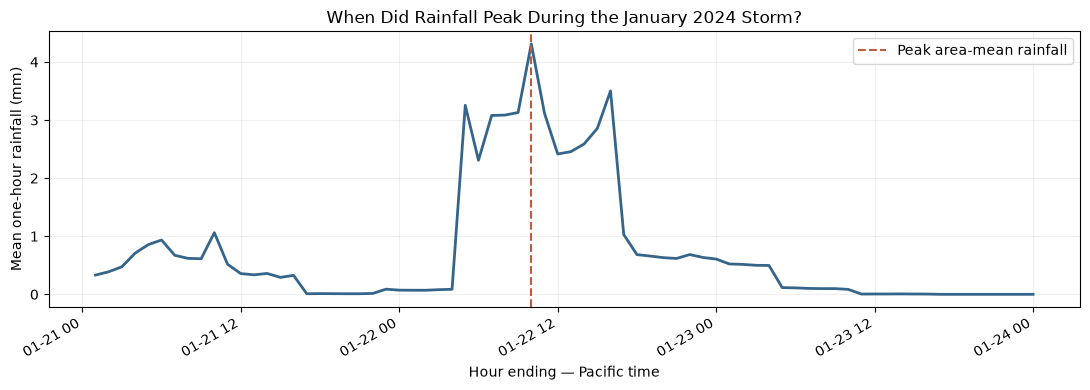

Peak hour ends: 2024-01-22 10:00:00-08:00
Peak area-mean rainfall: 4.31 mm


In [3]:
import matplotlib.pyplot as plt

hourly = (
    df.groupby("hour_end_pacific")["rainfall_mm"]
    .mean()
    .sort_index()
)

peak = hourly.idxmax()

fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(hourly.index, hourly.values, color="#35658a", linewidth=2)
ax.axvline(peak, color="#bd5b42", linestyle="--", label="Peak area-mean rainfall")

ax.set(
    title="When Did Rainfall Peak During the January 2024 Storm?",
    xlabel="Hour ending — Pacific time",
    ylabel="Mean one-hour rainfall (mm)",
)

ax.legend()
ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print("Peak hour ends:", peak)
print("Peak area-mean rainfall:", round(hourly.max(), 2), "mm")